# 02 · RFM analysis

**Goal:** describe every customer with three numbers and turn them into segments that a
marketing team can act on.

- **Recency:** days since the last purchase. Lower is better.
- **Frequency:** number of orders (invoices). Higher is better.
- **Monetary:** net spend, i.e. purchases minus the unpaired returns kept in phase 1.

RFM is simple, but it captures the three things that best predict whether a customer will buy
again: how recently, how often and how much.

The input is the clean data from `01_data_cleaning.ipynb`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src import rfm as rfm_lib

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

transactions = pd.read_parquet(PROCESSED_DIR / "transactions.parquet")
returns = pd.read_parquet(PROCESSED_DIR / "returns.parquet")

# Chart colours (shared with the other notebooks)
BLUE, ORANGE, TEXT, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

def style_axis(ax):
    """Light, recessive axes so the data stands out."""
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

## Snapshot date

RFM is always measured *at* a date. Here it is 2011-12-10, the day after the last purchase in
the data, so a customer who bought on the last day has recency 1.

The functions in `src/rfm.py` take the snapshot date as a parameter and only use data before it.
This matters for phase 5: churn features must be computed at a past cutoff, and this table,
which contains everything up to December 2011, cannot be reused there without leaking the future.

In [2]:
SNAPSHOT = transactions["invoice_date"].max().normalize() + pd.Timedelta(days=1)
print(f"Snapshot date: {SNAPSHOT:%Y-%m-%d}")

rfm = rfm_lib.compute_rfm(transactions, returns, SNAPSHOT)
print(f"{len(rfm):,} customers")
rfm.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1)

Snapshot date: 2011-12-10
5,839 customers


,recency,frequency,monetary
count,5839.0,5839.0,5839.0
mean,200.9,6.2,2801.8
std,208.6,12.6,13840.0
min,1.0,1.0,-1343.2
25%,26.0,1.0,332.5
50%,96.0,3.0,842.4
75%,380.0,7.0,2173.6
90%,531.6,13.0,5250.9
99%,727.0,45.6,26525.1
max,739.0,369.0,578408.6


A few real customers show how the three numbers describe very different behaviours:

In [3]:
examples = {
    14911: "buys all the time",
    17850: "very loyal, silent for a year",
    13902: "large wholesaler, gone since 2010",
    12367: "first order a few days ago",
}
rfm.loc[list(examples)].assign(note=list(examples.values())).round(0)

,recency,frequency,monetary,note
customer_id,,,,
14911,2,369,258522.0,buys all the time
17850,373,155,50408.0,"very loyal, silent for a year"
13902,633,5,30375.0,"large wholesaler, gone since 2010"
12367,5,1,151.0,first order a few days ago


## Distributions

All three dimensions are strongly skewed: most customers bought a few times for a few hundred
pounds, while a small group buys hundreds of times. Frequency and monetary are shown on a log
scale. This skew is why phase 3 will cluster on log-transformed values rather than raw ones.

The recency histogram also has a bump around 370 days and another near 730: customers whose last
purchase was in early December 2010 or December 2009. Some customers seem to buy only before
Christmas, which the churn phase will need to take into account.

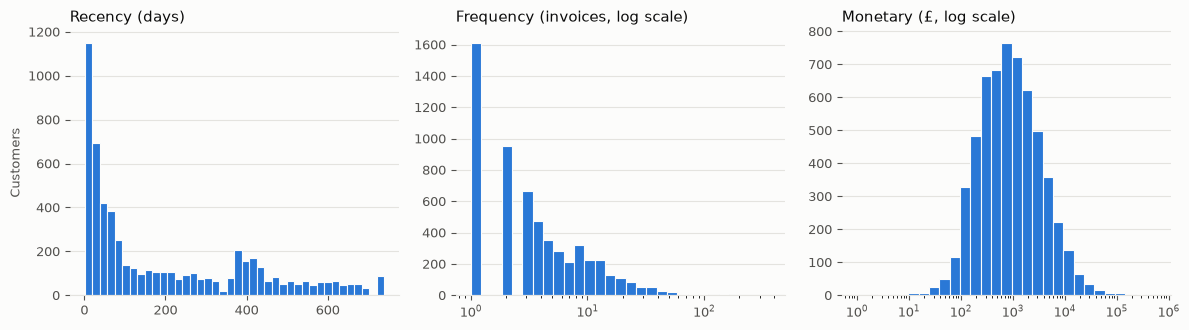

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), facecolor=SURFACE)

axes[0].hist(rfm["recency"], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
axes[0].set_title("Recency (days)", loc="left", color=TEXT, fontsize=11)

axes[1].hist(rfm["frequency"], bins=np.logspace(0, np.log10(rfm["frequency"].max()), 30),
             color=BLUE, edgecolor=SURFACE, linewidth=0.8)
axes[1].set_xscale("log")
axes[1].set_title("Frequency (invoices, log scale)", loc="left", color=TEXT, fontsize=11)

positive = rfm.loc[rfm["monetary"] > 0, "monetary"]
axes[2].hist(positive, bins=np.logspace(0, np.log10(positive.max()), 30),
             color=BLUE, edgecolor=SURFACE, linewidth=0.8)
axes[2].set_xscale("log")
axes[2].set_title("Monetary (£, log scale)", loc="left", color=TEXT, fontsize=11)

for ax in axes:
    style_axis(ax)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Customers", color=MUTED, fontsize=9)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_rfm_distributions.png", dpi=150, facecolor=SURFACE)
plt.show()

## Revenue concentration

Before scoring, it is worth checking how concentrated revenue is, because it tells the business
where to focus.

In [5]:
ranked = rfm["monetary"].sort_values(ascending=False)
for share in (0.01, 0.10, 0.20):
    top = ranked.head(int(len(ranked) * share))
    print(f"Top {share:.0%} of customers: {top.sum() / ranked.sum():.0%} of net revenue")

Top 1% of customers: 31% of net revenue
Top 10% of customers: 63% of net revenue
Top 20% of customers: 77% of net revenue


The classic 80/20 rule holds almost exactly: the best 20% of customers generate about three
quarters of net revenue. Losing a few of them costs more than losing hundreds of occasional buyers.

## Scores from 1 to 5

Each dimension gets a score from 1 (worst) to 5 (best), so that customers can be compared on
the same scale.

- **Recency and monetary:** quintiles, i.e. five groups with 20% of customers each. The recency
  labels are reversed, because fewer days since the last purchase is better.
- **Frequency:** quintiles do not work, as shown below.

In [6]:
single_order = (rfm["frequency"] == 1).mean()
print(f"Customers with exactly one invoice: {single_order:.1%}")

# Option A: plain quintiles. Edges collapse because of the ties, leaving only 4 groups
print("\nQuintile edges:", pd.qcut(rfm["frequency"], 5, duplicates="drop").cat.categories.tolist())

# Option B: break ties by rank. Identical customers end up with different scores
by_rank = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
print("Scores given to customers with 1 invoice:",
      by_rank[rfm["frequency"] == 1].value_counts().sort_index().to_dict())

Customers with exactly one invoice: 27.6%

Quintile edges: [Interval(0.999, 2.0, closed='right'), Interval(2.0, 4.0, closed='right'), Interval(4.0, 8.0, closed='right'), Interval(8.0, 369.0, closed='right')]
Scores given to customers with 1 invoice: {1: 1168, 2: 445, 3: 0, 4: 0, 5: 0}


More than 20% of the customers share the same value (one invoice), so the first quintile cannot be
cut. Plain quintiles merge two groups; breaking ties by rank gives two customers with exactly the
same history different scores, depending only on their order in the table.

The frequency score therefore uses **fixed thresholds**: 1 / 2 / 3–4 / 5–9 / 10+ invoices. They are
easy to explain and each group still contains 16–28% of the customers.

In [7]:
scored = rfm_lib.score_rfm(rfm)

score_shares = pd.DataFrame({
    col: scored[col].value_counts(normalize=True).sort_index()
    for col in ("r_score", "f_score", "m_score")
})
score_shares.style.format("{:.1%}")

,r_score,f_score,m_score
1,20.0%,27.6%,20.0%
2,20.0%,16.3%,20.0%
3,19.9%,19.6%,20.0%
4,19.4%,20.1%,20.0%
5,20.8%,16.4%,20.0%


## Named segments

Three scores from 1 to 5 give 125 combinations, too many to act on. The standard approach is to
build segments on **recency and frequency** only, with a grid like this one
(`SEGMENT_RULES` in `src/rfm.py`):

| | F = 1 | F = 2 | F = 3 | F = 4 | F = 5 |
|---|---|---|---|---|---|
| **R = 5** | New customers | Potential loyalists | Potential loyalists | Champions | Champions |
| **R = 4** | Promising | Potential loyalists | Potential loyalists | Loyal | Loyal |
| **R = 3** | About to sleep | About to sleep | Need attention | Loyal | Loyal |
| **R = 2** | Hibernating | Hibernating | At risk | At risk | Can't lose |
| **R = 1** | Hibernating | Hibernating | At risk | At risk | Can't lose |

Monetary is left out of the grid because it moves together with frequency: customers who order
more often also spend more in total. It is used instead to describe how valuable each segment is.

In [8]:
rfm[["recency", "frequency", "monetary"]].corr(method="spearman").round(2)

,recency,frequency,monetary
recency,1.00,-0.56,-0.51
frequency,-0.56,1.00,0.86
monetary,-0.51,0.86,1.00


A Spearman correlation of 0.86 between frequency and monetary confirms that adding monetary
to the grid would mostly repeat information already there. Spearman is used instead of Pearson
because it works on ranks and is not dominated by the few extreme customers.

In [9]:
scored["segment"] = rfm_lib.assign_segments(scored)
scored.loc[list(examples), ["recency", "frequency", "monetary", "r_score", "f_score", "m_score", "segment"]]

,recency,frequency,monetary,r_score,f_score,m_score,segment
customer_id,,,,,,,
14911,2,369,258522.43,5,5,5,Champions
17850,373,155,50407.77,2,5,5,Can't lose
13902,633,5,30375.26,1,4,5,At risk
12367,5,1,150.90,5,1,1,New customers


In [10]:
summary = (scored
           .groupby("segment", observed=False)
           .agg(customers=("recency", "size"),
                median_recency=("recency", "median"),
                median_frequency=("frequency", "median"),
                median_monetary=("monetary", "median"),
                revenue=("monetary", "sum")))
summary["share_of_customers"] = summary["customers"] / summary["customers"].sum()
summary["share_of_revenue"] = summary["revenue"] / summary["revenue"].sum()
summary = summary.drop(columns="revenue")

summary.style.format({
    "customers": "{:,}", "median_recency": "{:.0f}", "median_frequency": "{:.0f}",
    "median_monetary": "£{:,.0f}", "share_of_customers": "{:.1%}", "share_of_revenue": "{:.1%}",
})

,customers,median_recency,median_frequency,median_monetary,share_of_customers,share_of_revenue
segment,,,,,,
Champions,822,9,12,"£3,971",14.1%,52.4%
Loyal,"1,027",54,8,"£2,729",17.6%,26.8%
Potential loyalists,715,24,3,£739,12.2%,4.2%
New customers,77,12,1,£255,1.3%,0.2%
Promising,161,39,1,£225,2.8%,0.3%
Need attention,281,104,3,£975,4.8%,2.0%
About to sleep,421,96,1,£364,7.2%,1.6%
Can't lose,57,307,13,"£3,924",1.0%,2.7%
At risk,646,370,4,"£1,055",11.1%,5.4%


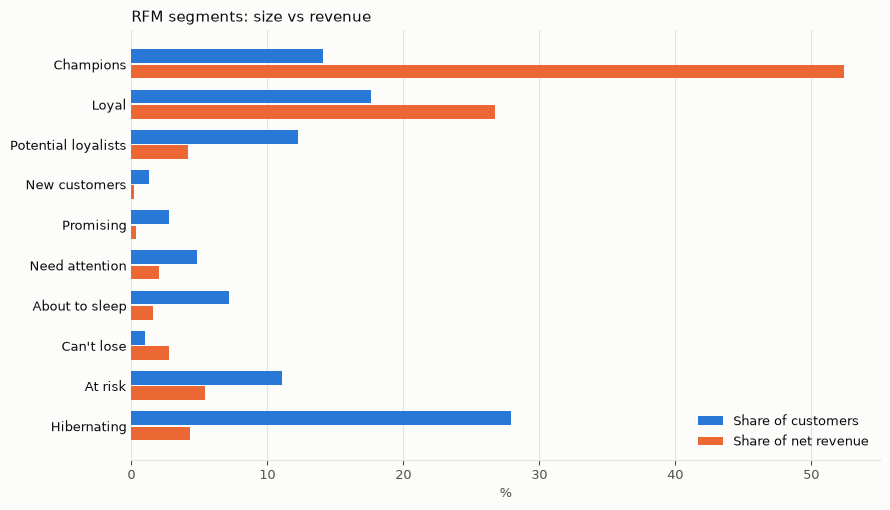

In [11]:
order = summary.index[::-1]  # first segment at the top
y = np.arange(len(order))
height = 0.38

fig, ax = plt.subplots(figsize=(9, 5.2), facecolor=SURFACE)
ax.barh(y + height / 2, summary.loc[order, "share_of_customers"] * 100, height=height - 0.04,
        color=BLUE, label="Share of customers")
ax.barh(y - height / 2, summary.loc[order, "share_of_revenue"] * 100, height=height - 0.04,
        color=ORANGE, label="Share of net revenue")

ax.set_yticks(y, order)
ax.set_xlabel("%", color=MUTED, fontsize=9)
ax.set_title("RFM segments: size vs revenue", loc="left", color=TEXT, fontsize=11)
style_axis(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", colors=TEXT, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right", fontsize=9, labelcolor=TEXT)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_rfm_segments.png", dpi=150, facecolor=SURFACE)
plt.show()

## Reading the segments

The chart shows the two ends of the customer base:

- **Champions and Loyal** are about a third of the customers but generate around 80% of net revenue.
- **Hibernating** is the largest segment, more than a quarter of the customers, but contributes only a
  few percent of revenue: mostly one or two orders, a long time ago.
- **Can't lose** is only 1% of the customers but earns more revenue than New customers, Promising and
  About to sleep combined (twelve times as many people). These were frequent buyers who have gone quiet.

## Recommended marketing actions

| Segment | Who they are | Recommended action |
|---|---|---|
| Champions | Bought recently and very often | Reward them: early access to new collections, loyalty perks. No discounts needed |
| Loyal | Frequent buyers, slightly less recent | Upsell and cross-sell, ask for reviews and referrals |
| Potential loyalists | Recent, 2–4 orders | Push towards a habit: volume offers, reminders before the Christmas season |
| New customers | One order in the last few weeks | Onboarding: welcome email, best sellers, a reason to place the second order |
| Promising | One recent-ish order | Light-touch follow-up with personalised recommendations |
| Need attention | Average on both recency and frequency | Time-limited offer based on what they bought before |
| About to sleep | Few orders, getting less recent | Reactivation email before they become hibernating |
| Can't lose | Were very frequent, gone quiet | Highest priority win-back: personal contact from an account manager, find out why they left |
| At risk | Several orders, but long ago | Win-back campaign with a meaningful incentive |
| Hibernating | One or two orders, long ago | Low-cost automated campaigns only; do not spend much on them |

The value of a segment, not only its size, should decide the budget: one Can't lose customer is
worth on average far more than one Hibernating customer.

## Save the RFM table

In [12]:
scored.to_parquet(PROCESSED_DIR / "rfm.parquet")
print(f"Saved {len(scored):,} customers to {PROCESSED_DIR.name}/rfm.parquet")

Saved 5,839 customers to processed/rfm.parquet


## Summary

| Choice | Decision | Reason |
|---|---|---|
| Snapshot | 2011-12-10, as a function parameter | Lets phase 5 recompute RFM at a past cutoff without leakage |
| Frequency | Distinct invoices, not lines | One invoice = one decision to buy, regardless of how many products |
| Monetary | Net of unpaired returns | Uses the returns table kept in phase 1 |
| R and M scores | Quintiles | Continuous values, balanced groups |
| F score | Fixed thresholds 1 / 2 / 3–4 / 5–9 / 10+ | 27.6% of customers have one invoice, so quintiles break |
| Segments | Standard R × F grid, monetary used to describe | F and M are highly correlated (Spearman 0.86); 125 combinations are not actionable |

**Next:** phase 3 clusters customers on log-transformed recency, frequency and monetary and compares
the data-driven segments with these rule-based ones.